##### In this notebook, the two methods for extending the base period of a travelling wave are explored and compared

The methods are:
- Tiling, where one adds a copy to the end of the wave-array
- Padding, where one simply adds zeros (or an appropriate value) to the array


In [ ]:
import sys
from pathlib import Path

root = Path.cwd().parent.parent
sys.path.insert(0,str(root))

from camera.camera_file import Camera
from camera.spectralCamera import *
from camera.pdeCamera import *
from camera.lsmCamera import LSM
from camera.help import *

from waves.waveGenCamera import *
from waves. soliton import kdv_cnoidal, soliton

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt

In [39]:
# General set-up:
L = 4*np.pi
N = 2**7
dt = 1e-3

c1 = Camera(L,N,dt)

T=0.5

In [40]:
# Wave set-up
P = 2*np.pi
amp = 1
mean = 0

wp = KdVNewton(P,amp,mean,c1)
wp.solve_w_continuation()

phi = wp.get_physical(wp.phi_hat_mid)

x = np.linspace(-P/2, P/2, N//2)
k = nf.rfftfreq(N//2, c1.dx)*2*np.pi

#### Tiling 
As seen in the cnoidal1 notebook, the waves generated are of the form of a theoretical travelling wave for the KdV equation. 
When the field of view $L$ is a whole multiple $m$ of the wave-period $P$, tiling the wave uses the periodic assumption and looks at $m$ periods of the wave crossing $L$. 
This has the same effect as saying only every $m$-th Fourier mode has a non-zero value. 

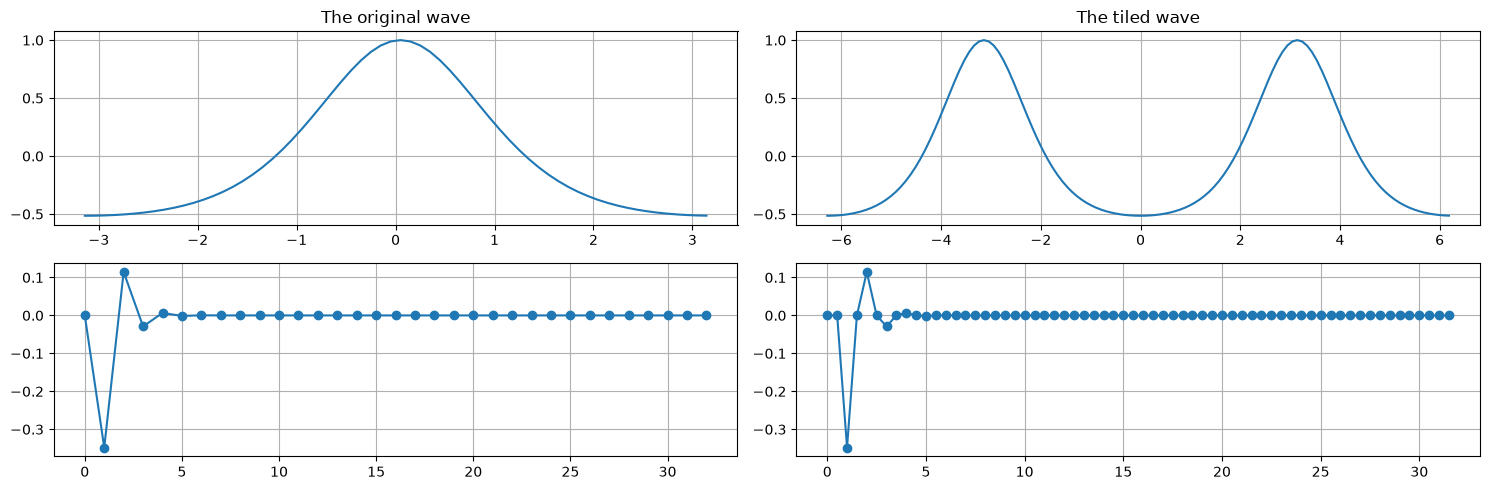

In [41]:
m = int(L//P) # assuming it is integer
phi_tiled = np.tile(phi,m)

fig, ax = plt.subplots(2,2, figsize = (15,5))
ax[0,0].set_title("The original wave")
ax[0,1].set_title("The tiled wave")


ax[0,0].plot(x,phi)
ax[0,1].plot(c1.x, np.tile(phi,2))

ax[0,0].grid()
ax[0,1].grid()

ax[1,0].plot(k,wp.phi_hat_mid.real, '-o')
ax[1,1].plot(c1.k[:N//2], nf.fft(phi_tiled).real[:N//2]/(N), '-o')

ax[1,0].grid()
ax[1,1].grid()

fig.tight_layout()

plt.show()


As the wave is tiled there is no - added - radiation in the forward solution. <br>
Tiling can also be added post solving forward lowering the computation cost.

#### Padding
For padding the picture is a bit more complex. If the waves have a long period compared to the window, and the elliptic factor $m$ is not close to $1$, then there might be edge effects that are lost in the padding. For traveling solitions however, the far-away field is unaffected by the wave, and padding might be possible. Let us first see a wave that is not a soliton:

The value of m is: 0.940


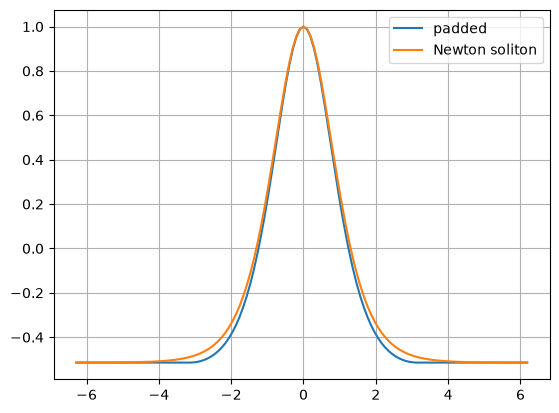

In [42]:
# cnoidal wave based on newton sovler
phi_cn, c_cn, m = kdv_cnoidal(P,amp, mean,x,0)
print(F"The value of m is: {m:.3f}")

# #cnoidal wave over L:
# phi_cn_w, c_cn_w, mw = kdv_cnoidal(P,amp,mean, c1.x,0)
# print(F"The value of mw is: {mw:.3f}")
# Newton soliton



# Lets try padding: 
min = np.abs(np.min(phi))

padded = np.zeros(c1.N) - min
padded[wp.N//2:3*wp.N//2] = phi


#creating a sech^2 wave for comparison
sol = soliton(c1.x, 2*(amp+min), 0) - min

plt.plot(c1.x, padded, label ='padded')
plt.plot(c1.x, sol, label ='Newton soliton')
# plt.plot(c1.x,phi_cn_w[0], label = 'cn')
plt.grid()
plt.legend()
plt.show()



The value of m2 is: 0.999


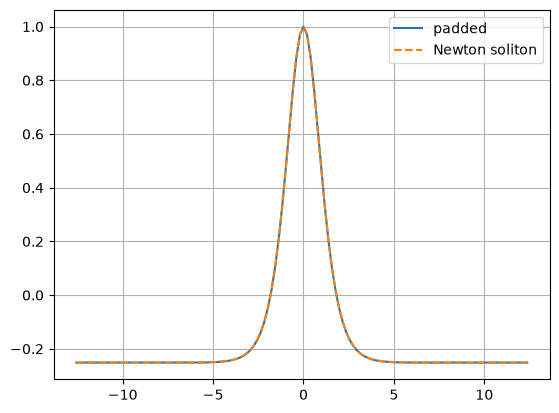

In [48]:
#And now creating a wave that is more solitonic. 

L2 = 8*np.pi
N2 = 2**7
dt2 = 1e-3

c2 = Camera(L2,N2,dt2)

T=0.5

P2 = 4*np.pi
amp = 1
mean = 0

wp2 = KdVNewton(P2,amp,mean,c2)
wp2.solve_w_continuation()

phi2 = wp2.get_physical(wp2.phi_hat_mid)

x2 = np.linspace(-P2/2, P2/2, N2//2)
k2 = nf.rfftfreq(N2//2, c2.dx)*2*np.pi

phi_cn2, c_cn2, m2 = kdv_cnoidal(P2,amp, mean,x2,0)
print(F"The value of m2 is: {m2:.3f}")

#creating a sech^2 wave for comparison
min = np.abs(np.min(phi2))
sol2 = soliton(c2.x, 2*(amp+min), 0) - min


# Lets try padding: 
padded2 = np.zeros(c2.N) - min
padded2[wp2.N//2:3*wp2.N//2] = phi2

plt.plot(c2.x, padded2, label ='padded')
plt.plot(c2.x, sol2, label ='Newton soliton', linestyle = '--')
# plt.plot(c1.x,phi_cn_w[0], label = 'cn')
plt.grid()
plt.legend()
plt.show()

Solving both of these waves forward in time we can compare their errors <br>
Would i rater try to pad on a cn wave? and from this conclude that padding only can be done without loss when $m=1$ ???

In [ ]:
inital = [phi, sol , phi2, sol2]
